In [1]:
pip install pandas numpy matplotlib seaborn xgboost prophet scikit-learn streamlit plotly 

   ---------------------------------------- 0.0/48.9 MB ? eta -:--:--
   ---------------------------------------- 0.3/48.9 MB ? eta -:--:--
   - -------------------------------------- 1.3/48.9 MB 4.8 MB/s eta 0:00:10
   -- ------------------------------------- 3.7/48.9 MB 8.1 MB/s eta 0:00:06
   ----- ---------------------------------- 6.3/48.9 MB 9.6 MB/s eta 0:00:05
   --------- ------------------------------ 11.8/48.9 MB 13.9 MB/s eta 0:00:03
   ------------ --------------------------- 15.5/48.9 MB 15.2 MB/s eta 0:00:03
   -------------- ------------------------- 17.3/48.9 MB 14.2 MB/s eta 0:00:03
   --------------- ------------------------ 18.9/48.9 MB 12.9 MB/s eta 0:00:03
   ---------------- ----------------------- 19.9/48.9 MB 12.1 MB/s eta 0:00:03
   ----------------- ---------------------- 21.0/48.9 MB 11.4 MB/s eta 0:00:03
   ------------------ --------------------- 22.3/48.9 MB 10.8 MB/s eta 0:00:03
   ------------------- -------------------- 23.6/48.9 MB 10.4 MB/s eta 0:00:

In [2]:
pip install ipykernel

Note: you may need to restart the kernel to use updated packages.


In [3]:
# ==========================================
# CELL 1: IMPORT REQUIRED LIBRARIES
# ==========================================
# We import data manipulation tools (pandas, numpy), 
# visualization tools (matplotlib, seaborn), 
# and machine learning models (xgboost, prophet).
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import xgboost as xgb
from prophet import Prophet
from sklearn.metrics import mean_absolute_error, mean_absolute_percentage_error
import warnings

# Ignore warning messages to keep the notebook output clean
warnings.filterwarnings('ignore')

In [4]:
# ==========================================
# CELL 2: LOAD DATA & RECONSTRUCT TIMELINE
# ==========================================
# The dataset has 'transaction_time' but is missing the actual calendar date.
# We must mathematically detect when a new day starts to build a continuous timeline.

print("Loading dataset...")
df = pd.read_csv('Afficionado Coffee Roasters.xlsx - Transactions.csv')

# Convert the transaction_time string (e.g., "7:06:11") into a measurable time duration
df['time'] = pd.to_timedelta(df['transaction_time'])

# Calculate the difference in seconds between consecutive transactions
df['time_diff'] = df['time'].diff().dt.total_seconds()

# If the time jumps backwards by a large amount (e.g., from 8 PM to 7 AM), 
# the difference will be highly negative. We use -40,000 seconds as the threshold 
# to flag that the store closed and reopened for a new day.
df['is_new_day'] = (df['time_diff'] < -40000).astype(int)

# Cumulative sum counts how many "new days" have passed since the first row
df['day_index'] = df['is_new_day'].cumsum()

# Assume the data starts on Jan 1, 2025. We add the day_index to create real dates.
df['transaction_date'] = pd.to_datetime('2025-01-01') + pd.to_timedelta(df['day_index'], unit='D')

# Combine the new date and the original time into a single DateTime column
df['datetime'] = df['transaction_date'] + df['time']

# Extract the hour of the day (0-23) for our hourly forecasting models
df['hour'] = df['datetime'].dt.hour

# Calculate total revenue per transaction (Quantity * Price)
df['revenue'] = df['transaction_qty'] * df['unit_price']

print("Timeline successfully reconstructed. Total rows:", len(df))
display(df[['transaction_date', 'transaction_time', 'hour', 'revenue']].head())

Loading dataset...
Timeline successfully reconstructed. Total rows: 149116


,transaction_date,transaction_time,hour,revenue
0,2025-01-01,7:06:11,7,6.0
1,2025-01-01,7:08:56,7,6.2
2,2025-01-01,7:14:04,7,9.0
3,2025-01-01,7:20:24,7,2.0
4,2025-01-01,7:22:41,7,6.2


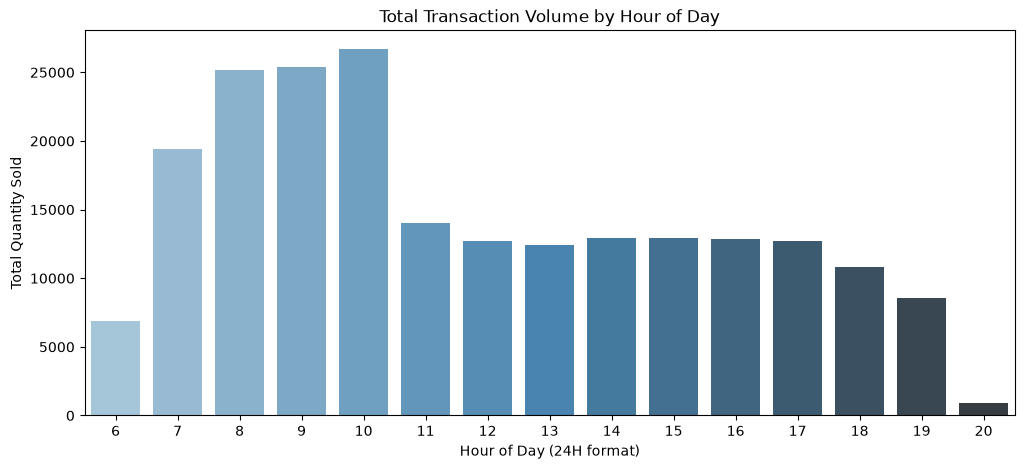

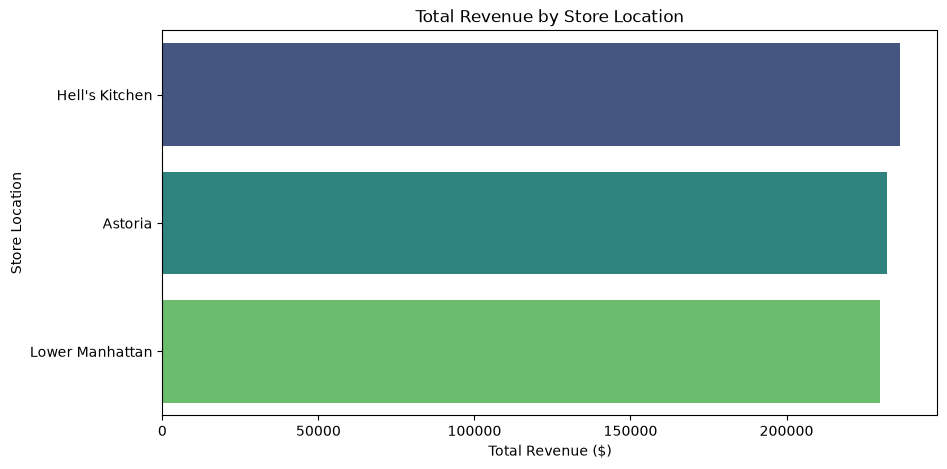

In [5]:
# ==========================================
# CELL 3: EXPLORATORY DATA ANALYSIS (EDA)
# ==========================================
# Before modeling, we visualize the data to understand demand patterns. 
# This will be useful for your research paper submission.

plt.figure(figsize=(12, 5))

# 1. Visualize overall hourly traffic to identify peak rush hours
hourly_traffic = df.groupby('hour')['transaction_qty'].sum()
sns.barplot(x=hourly_traffic.index, y=hourly_traffic.values, palette="Blues_d")
plt.title("Total Transaction Volume by Hour of Day")
plt.xlabel("Hour of Day (24H format)")
plt.ylabel("Total Quantity Sold")
plt.show()

# 2. Visualize revenue distribution across different stores
plt.figure(figsize=(10, 5))
store_revenue = df.groupby('store_location')['revenue'].sum().sort_values(ascending=False)
sns.barplot(x=store_revenue.values, y=store_revenue.index, palette="viridis")
plt.title("Total Revenue by Store Location")
plt.xlabel("Total Revenue ($)")
plt.ylabel("Store Location")
plt.show()

In [6]:
# ==========================================
# CELL 4: FEATURE ENGINEERING FOR HOURLY DEMAND
# ==========================================
# We need to aggregate the individual transactions into hourly buckets per store.
# Then, we create "Lag Features" (what happened yesterday at this exact same time) 
# to help the XGBoost model predict tomorrow's demand.

# Aggregate data: Sum of transaction_qty per store, per day, per hour
hourly_df = df.groupby(['transaction_date', 'hour', 'store_id'])['transaction_qty'].sum().reset_index()

# Add a feature for the day of the week (0 = Monday, 6 = Sunday)
# Demand behaves differently on weekends vs weekdays
hourly_df['day_of_week'] = hourly_df['transaction_date'].dt.dayofweek

# Sort chronologically to ensure our shift (lag) calculation is accurate
hourly_df = hourly_df.sort_values(by=['store_id', 'transaction_date', 'hour'])

# Create a Lag Feature: Demand from 24 hours ago for the same store
# This gives the model historical context for the specific hour
hourly_df['lag_24h'] = hourly_df.groupby(['store_id', 'hour'])['transaction_qty'].shift(1)

# Drop rows where lag_24h is NaN (the very first day of data for each store)
hourly_df = hourly_df.dropna()

display(hourly_df.head())

,transaction_date,hour,store_id,transaction_qty,day_of_week,lag_24h
40,2025-01-02,11,3,38,3,31.0
43,2025-01-02,12,3,36,3,40.0
46,2025-01-02,13,3,34,3,31.0
49,2025-01-02,14,3,28,3,22.0
52,2025-01-02,15,3,27,3,30.0


In [9]:
# ==========================================
# CELL 5: XGBOOST MODEL TRAINING (FIXED FOR DASHBOARD)
# ==========================================
features = ['hour', 'day_of_week', 'store_id', 'lag_24h']
target = 'transaction_qty'

X = hourly_df[features]
y = hourly_df[target]

# Split data for training
split_idx = int(len(X) * 0.8)
X_train, X_test = X.iloc[:split_idx], X.iloc[split_idx:]
y_train, y_test = y.iloc[:split_idx], y.iloc[split_idx:]

# Train the model
xgb_model = xgb.XGBRegressor(n_estimators=100, learning_rate=0.1, max_depth=5, random_state=42)
xgb_model.fit(X_train, y_train)

# Calculate Error on the test set
test_preds = xgb_model.predict(X_test)
mae = mean_absolute_error(y_test, np.round(test_preds))
print(f"XGBoost Hourly Model MAE: {mae:.2f} transactions")

# FIX: Predict on the ENTIRE dataset (X) so all stores appear in the dashboard
full_predictions = xgb_model.predict(X)

# Save all predictions to the CSV
results = X.copy()
results['predicted_qty'] = np.round(full_predictions)
results['transaction_date'] = hourly_df['transaction_date']
results.to_csv('hourly_predictions.csv', index=False)
print("Updated hourly predictions saved for ALL stores!")

XGBoost Hourly Model MAE: 13.56 transactions
Updated hourly predictions saved for ALL stores!


In [10]:
# ==========================================
# CELL 6: PROPHET MODEL TRAINING (DAILY REVENUE)
# ==========================================
# We use Facebook Prophet to forecast medium-term (14-30 days) daily revenue.
# Prophet excels at handling weekly seasonality (e.g., weekends always being busier).

# Aggregate data: Sum of revenue per store, per day
daily_df = df.groupby(['transaction_date', 'store_id'])['revenue'].sum().reset_index()

forecast_results = []

# Train a separate Prophet model for each unique store
for store in daily_df['store_id'].unique():
    
    # Filter data for the current store
    store_data = daily_df[daily_df['store_id'] == store].copy()
    
    # Prophet strictly requires columns to be named 'ds' (datestamp) and 'y' (target variable)
    store_data = store_data.rename(columns={'transaction_date': 'ds', 'revenue': 'y'})
    
    # We will use all data except the last 30 days to train
    train_data = store_data.iloc[:-30]
    
    # Initialize Prophet. We enable weekly seasonality but disable yearly 
    # since we only have a few months of data.
    m = Prophet(yearly_seasonality=False, weekly_seasonality=True)
    m.fit(train_data)
    
    # Instruct Prophet to predict 30 days into the future
    future = m.make_future_dataframe(periods=30)
    forecast = m.predict(future)
    
    # Add the store_id back so we know which store this forecast belongs to
    forecast['store_id'] = store
    
    # Keep only the essential columns: date, predicted value (yhat), and confidence intervals
    forecast_results.append(forecast[['ds', 'yhat', 'yhat_lower', 'yhat_upper', 'store_id']])

# Combine all store forecasts into one DataFrame and save for Streamlit
daily_forecast_df = pd.concat(forecast_results)
daily_forecast_df.to_csv('daily_forecasts.csv', index=False)
print("Daily revenue forecasts saved to 'daily_forecasts.csv'")

16:50:42 - cmdstanpy - INFO - Chain [1] start processing
16:50:42 - cmdstanpy - INFO - Chain [1] done processing
16:50:42 - cmdstanpy - INFO - Chain [1] start processing
16:50:42 - cmdstanpy - INFO - Chain [1] done processing
16:50:42 - cmdstanpy - INFO - Chain [1] start processing
16:50:42 - cmdstanpy - INFO - Chain [1] done processing


Daily revenue forecasts saved to 'daily_forecasts.csv'
